In [2]:
from matplotlib import pyplot as plt
import numpy as np
from collections import deque

In [ ]:
class Image:
    N4 = [(-1, 0), (1, 0), (0, -1), (0, 1)]   
    Nd = [(-1, -1), (-1, 1), (1, -1), (1, 1)]

    def __init__(self, img):
        self.img = img
        self.rows, self.cols = img.shape

    def show(self):
        plt.imshow(self.img, cmap='binary_r')
        plt.show()

    def get_neighbors(self, P, con, V={1}):
        r, c = P
        nbr = []

        if con == 4:
            for dr, dc in self.N4:
                nr, nc = r + dr, c + dc
                if 0 <= nr < self.rows and 0 <= nc < self.cols:
                    if self.img[nr, nc] in V:
                        nbr.append((nr, nc))

        elif con == 8:
            for dr, dc in self.N4 + self.Nd:
                nr, nc = r + dr, c + dc
                if 0 <= nr < self.rows and 0 <= nc < self.cols:
                    if self.img[nr, nc] in V:
                        nbr.append((nr, nc))

        elif con == 'm':
            for dr, dc in self.N4:
                nr, nc = r + dr, c + dc
                if 0 <= nr < self.rows and 0 <= nc < self.cols:
                    if self.img[nr, nc] in V:
                        nbr.append((nr, nc))

            for dr, dc in self.Nd:
                nr, nc = r + dr, c + dc
                if 0 <= nr < self.rows and 0 <= nc < self.cols:
                    if self.img[nr, nc] in V:
                        common = []
                        for adr, adc in self.Nadj:
                            ar, ac = r + adr, c + adc
                            if 0 <= ar < self.rows and 0 <= ac < self.cols:
                                if (abs(ar - nr) + abs(ac - nc)) == 1:
                                    if self.img[ar, ac] in V:
                                        common.append((ar, ac))

                        if len(common) == 0:
                            nbr.append((nr, nc))

        return nbr

    def bfs(self, start, end, con, V={1}):
        if self.img[start] not in V or self.img[end] not in V:
            return False

        visited = set()
        q = deque([start])
        visited.add(start)

        while q:
            current = q.popleft()

            if current == end:
                return True

            for neighbor in self.get_neighbors(current, con, V):
                if neighbor not in visited:
                    visited.add(neighbor)
                    queue.append(neighbor)

        return False

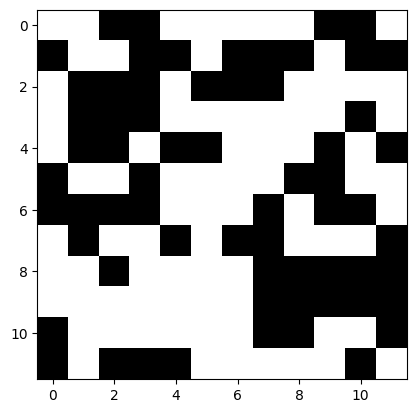

NameError: name 'conn_type' is not defined

In [8]:
np.random.seed(1)
img_arr = np.random.randint(0, 2, size=(12, 12))

img = Image(img_arr)
img.show()

start = (1, 5)
end = (9, 6)

print("4-connectivity:", img.bfs(start, end, 4))
print("8-connectivity:", img.bfs(start, end, 8))
print("m-connectivity:", img.bfs(start, end, 'm'))
